# Day 8: Your First Agent

LangChain in 10 Days · KGP Talkie · Laxmi Kant Tiwari · kgptalkie.com

**Today:** stop running the tool loop by hand, let the model decide what to do and how many times. Read the trace, watch it decide step by step, cap the loop, and give the agent a memory.

In [3]:
import time

from dotenv import load_dotenv
from langchain_openrouter import ChatOpenRouter
from langchain.tools import tool
from langchain.messages import HumanMessage

load_dotenv()

model = ChatOpenRouter(model="nvidia/nemotron-3.5-lightning:free", temperature=0)

## 1. Rebuild yesterday's two tools

In [4]:
import ollama

@tool
def multiply(a: float, b: float) -> float:
    """Multiply two numbers together and return the exact result."""
    return a * b

@tool
def web_search(query: str) -> str:
    """Search the live web and return the top results. Use for questions about current events, prices or rates."""
    results = ollama.web_search(query, max_results=3).results
    parts = []
    for r in results:
        parts.append(r.title + " (" + r.url + ")\n" + r.content[:300])
    return "\n\n".join(parts)

Yesterday you did the middle part yourself: read `tool_calls`, run the function, wrap it in a `ToolMessage`, call the model again.

That loop never changes. Today something else runs it.

## 2. Build an agent with create_agent

In [5]:
from langchain.agents import create_agent

agent = create_agent(
    model=model,
    tools=[multiply, web_search],
    system_prompt="""You are a helpful assistant.
Always use a tool for any calculation. Never do arithmetic yourself.
Use web_search for live information such as exchange rates.""",
)

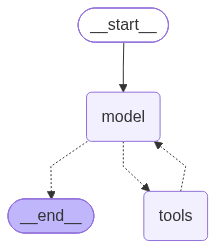

In [6]:
agent

A model, the tools it may use, and one instruction about when to use them.

## 3. Ask it something that needs two steps

In [7]:
question = "I am buying 12 items at 250 dollars each. How many rupees is that at today's exchange rate?"

result = agent.invoke({"messages": [HumanMessage(question)]})

result

{'messages': [HumanMessage(content="I am buying 12 items at 250 dollars each. How many rupees is that at today's exchange rate?", additional_kwargs={}, response_metadata={}, id='034d0e32-a8c3-411b-a593-9add40166b03'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'We need to calculate total dollars: 12 * 250 = 3000 dollars. Then convert to rupees at today\'s exchange rate. Use web_search to get today\'s USD to INR exchange rate. Then multiply 3000 by that rate. Use multiply tool.\n\nFirst, search "USD to INR exchange rate today".', 'reasoning_details': [{'type': 'reasoning.text', 'format': 'unknown', 'index': 0, 'text': 'We need to calculate total dollars: 12 * 250 = 3000 dollars. Then convert to rupees at today\'s exchange rate. Use web_search to get today\'s USD to INR exchange rate. Then multiply 3000 by that rate. Use multiply tool.\n\nFirst, search "USD to INR exchange rate today".'}]}, response_metadata={'model_name': 'nvidia/nemotron-3.5-lightning:free', 'id': 

Two tool calls happened, and you named neither. The agent fetched the live rate first, then multiplied by it, because the multiplication needs the rate. Nothing in your code said so.

Look closely at the trace in the next section, though: 12 × 250 became 3,000 **in its head**, despite the system prompt saying never to. A system prompt is still a suggestion, Day 2 told you why.

## 4. Read the trace: every step is a message

Every step is a message.

In [8]:
for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

I am buying 12 items at 250 dollars each. How many rupees is that at today's exchange rate?
================================== Ai Message ==================================
Tool Calls:
  web_search (call-5396bf90-d04e-47cd-90aa-1d9f42b0b785)
 Call ID: call-5396bf90-d04e-47cd-90aa-1d9f42b0b785
  Args:
    query: USD to INR exchange rate today
================================= Tool Message =================================
Name: web_search

USD INR | US Dollar Indian Rupee - Investing.com (https://www.investing.com/currencies/usd-inr)
USD INR | US Dollar Indian Rupee - Investing.com

Advertisement

Advertisement

# USD/INR - US Dollar Indian Rupee

Real-time Currencies

Currency in

INR

| Currency | Name |
| --- | --- |
| USD/INR | · | Indian Rupee |
| USD/JPY | · | Japanese Yen |
| USD/SGD | · | Singapore Dollar |
| USD/THB | ·

1 USD to INR - US Dollars to Indian Rupees Exchange Rate (https://www.xe.com/

Top to bottom:

1. **Human** asked the question.
2. **Ai** decided to call a tool and filled in the arguments.
3. **Tool** returned the real number, computed by Python.
4. Steps 2 and 3 repeat as often as the model decides.
5. **Ai** wrote the final sentence.

Exactly the loop you wrote by hand yesterday. The only new thing is who decides when to stop.

In a real product this list is the record that explains why your assistant
said what it said. Never throw it away.

## 5. Watch each decision with .stream()

`.stream()` shows each step as it completes, instead of waiting for the final answer.

In [12]:
result['messages'][-1].text

'The total cost in U.S. dollars is  \n\n\\(12 \\times 250 = \\$3{,}000\\).\n\nUsing today’s exchange rate (1\u202fUSD\u202f≈\u202f95.7319\u202fINR, from a live source), the conversion is  \n\n\\(3{,}000 \\times 95.7319 \\approx \\mathbf{287{,}195.82\\;INR}\\).\n\nSo, 12 items at\u202f$250 each cost roughly **₹287,196** at today’s rate.'

In [14]:
# time.sleep(6)

for step in agent.stream(
    {"messages": [HumanMessage("What is 8 times 4 dollars in rupees?")]},
    stream_mode="updates",
):
    for node, update in step.items():
        # print('node: ', node)
        # print('\n\nupdate: ', update)
        last = update["messages"][-1]
        print(node + ": " + (last.text or str(last.tool_calls))[:90])

model: [{'name': 'web_search', 'args': {'query': 'USD to INR exchange rate'}, 'id': 'call-6c11255
tools: 1 USD to INR - US Dollars to Indian Rupees Exchange Rate (https://www.xe.com/currencyconve
model: [{'name': 'multiply', 'args': {'b': 95.7612296, 'a': 32}, 'id': 'call-be85c0e4-e51f-48ef-b
tools: 3064.3593472
model: 8 × $4 = $32.  

Using the current mid‑market exchange rate (1 USD ≈ 95.7612 INR):

$32 × 


`stream_mode="updates"` gives one item per completed step, how you'd build a "thinking..." display.

Also the best debugging tool here: a strange answer's reason is almost always visible in the middle steps, not the last one.

## 6. An agent costs more than a chain

An agent calls the model to decide, then again to answer. A chain makes one call and does exactly what you planned.

In [16]:
model.invoke("Say hello in one word.")

AIMessage(content='Hello', additional_kwargs={'reasoning_content': 'Here\'s a thinking process:\n\n1.  **Analyze User Input:** The user says "Say hello in one word."\n2.  **Identify Core Request:** The user wants a greeting, specifically in one word.\n3.  **Determine Response:** The most direct one-word hello is "Hello" itself, or common alternatives like "Hi", "Hey", "Hola", etc. Since the prompt is "Say hello in one word", the literal answer is "Hello". It fits the constraint (one word) and directly fulfills the request.\n4.  **Formulate Response:** Just output the word. I should keep it simple and direct. "Hello" is perfect.\n5.  **Check Constraints:** One word? Yes. Says hello? Yes.\n6.  **Final Output:** Hello', 'reasoning_details': [{'type': 'reasoning.text', 'format': 'unknown', 'index': 0, 'text': 'Here\'s a thinking process:\n\n1.  **Analyze User Input:** The user says "Say hello in one word."\n2.  **Identify Core Request:** The user wants a greeting, specifically in one word.

In [15]:
# time.sleep(6)

simple = agent.invoke({"messages": [HumanMessage("Say hello in one word.")]})

simple

{'messages': [HumanMessage(content='Say hello in one word.', additional_kwargs={}, response_metadata={}, id='1558266d-ab91-4fb7-be97-40044b8e8ad2'),
  AIMessage(content='Hello', additional_kwargs={'reasoning_content': 'The user says: "Say hello in one word." That\'s a simple request: output a single word that means hello. Probably "Hello". But they want one word. So answer "Hello". No tool needed. But the instruction says "Always use a tool for any calculation." This is not a calculation. It\'s just a phrase. There\'s no calculation. So we can just answer. However the system says "When users ask questions, you MUST use the available tools." But this is not a question that requires a tool. It\'s a simple instruction. I think we can just answer. But to be safe, maybe use web_search? Not needed. I\'ll just answer "Hello".', 'reasoning_details': [{'type': 'reasoning.text', 'format': 'unknown', 'index': 0, 'text': 'The user says: "Say hello in one word." That\'s a simple request: output a s

Even a trivial question costs at least two messages through an agent.

Every message in that trace carries its own `usage_metadata`, and an agent produces more of them than a chain does.

> Use a **chain** when you already know the steps. Use an **agent** when the next step depends on what came back.

An agent buys decisions, and decisions cost round trips.

## 7. Cap the loop with ModelCallLimitMiddleware

Nothing stops an agent looping yet. A tool returning something unsatisfying, or two tools disagreeing, and it keeps trying.

In [20]:
from langchain.agents.middleware import ModelCallLimitMiddleware

limited = create_agent(
    model=model,
    tools=[multiply, web_search],
    system_prompt="Always use a tool for any calculation.",
    middleware=[ModelCallLimitMiddleware(run_limit=2, exit_behavior="end")],
)

In [21]:
question

"I am buying 12 items at 250 dollars each. How many rupees is that at today's exchange rate?"

In [22]:
# time.sleep(6)

capped = limited.invoke({"messages": [HumanMessage(question)]})

capped

{'messages': [HumanMessage(content="I am buying 12 items at 250 dollars each. How many rupees is that at today's exchange rate?", additional_kwargs={}, response_metadata={}, id='d1551e2d-66f4-41f8-ad46-8857ec9f75ba'),
  AIMessage(content='', additional_kwargs={'reasoning_content': "We need to calculate total dollars: 12 * 250 = 3000 dollars. Then convert to rupees at today's exchange rate. Need to get today's exchange rate USD to INR. Use web_search to find current rate. Then multiply 3000 by rate. Use multiply tool. First search.", 'reasoning_details': [{'type': 'reasoning.text', 'format': 'unknown', 'index': 0, 'text': "We need to calculate total dollars: 12 * 250 = 3000 dollars. Then convert to rupees at today's exchange rate. Need to get today's exchange rate USD to INR. Use web_search to find current rate. Then multiply 3000 by rate. Use multiply tool. First search."}]}, response_metadata={'model_name': 'nvidia/nemotron-3.5-lightning:free', 'id': 'gen-1787134496-PvU8ZWycEpnd3h46eF

In [23]:
capped = limited.invoke({"messages": [HumanMessage("what is weather in mumbai")]})

capped

{'messages': [HumanMessage(content='what is weather in mumbai', additional_kwargs={}, response_metadata={}, id='3dd1fec6-98d2-49b4-975c-a539eea75168'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'The user asks: "what is weather in mumbai". Need current weather. Use web_search tool.', 'reasoning_details': [{'type': 'reasoning.text', 'format': 'unknown', 'index': 0, 'text': 'The user asks: "what is weather in mumbai". Need current weather. Use web_search tool.'}]}, response_metadata={'model_name': 'nvidia/nemotron-3.5-lightning:free', 'id': 'gen-1787134586-w39kqNZC37NvU8mlRsuo', 'created': 1787134586, 'object': 'chat.completion', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'openrouter', 'cost': 0.0, 'cost_details': {'upstream_inference_completions_cost': 0.0, 'upstream_inference_prompt_cost': 0.0, 'upstream_inference_cost': 0.0}}, id='lc_run--01a01985-9f90-7f32-b37a-cbe849b674ab-0', tool_calls=[{'name': 'web_search', 'args': {'query': 'current 

`run_limit` caps calls per question. `exit_behavior="end"` stops cleanly; `"error"` raises instead, useful in a batch job where a silent partial answer is worse than a failure.

Put a limit on anything unattended. An agent looping against a paid API is how you discover your billing alerts don't work.

## 8. Add Day 6's checkpointer to the agent

Day 6's checkpointer works here unchanged, this is where the two halves of the course meet.

In [24]:
from langgraph.checkpoint.memory import InMemorySaver

assistant = create_agent(
    model=model,
    tools=[multiply, web_search],
    system_prompt="You are a helpful shopping assistant. Use tools for arithmetic and web_search for exchange rates.",
    checkpointer=InMemorySaver(),
)

cfg = {"configurable": {"thread_id": "shopper"}}

In [25]:
# time.sleep(6)

response = assistant.invoke(
    {"messages": [HumanMessage("How many rupees is 40 dollars?")]},
    config=cfg,
)

response

{'messages': [HumanMessage(content='How many rupees is 40 dollars?', additional_kwargs={}, response_metadata={}, id='b000b4d7-0a96-4094-9045-ad9288d47b7a'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'We need to convert 40 dollars to rupees. Likely need current exchange rate. Use web_search for "40 USD to INR" or "dollar to rupee exchange rate". Then multiply. Let\'s search.', 'reasoning_details': [{'type': 'reasoning.text', 'format': 'unknown', 'index': 0, 'text': 'We need to convert 40 dollars to rupees. Likely need current exchange rate. Use web_search for "40 USD to INR" or "dollar to rupee exchange rate". Then multiply. Let\'s search.'}]}, response_metadata={'model_name': 'nvidia/nemotron-3.5-lightning:free', 'id': 'gen-1787134713-fiAdZ4y0k3fcivMyd3ba', 'created': 1787134713, 'object': 'chat.completion', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'openrouter', 'cost': 0.0, 'cost_details': {'upstream_inference_completions_cost': 0.0, 'up

In [26]:
# time.sleep(6)

response = assistant.invoke(
    {"messages": [HumanMessage("And if I buy three of them?")]},
    config=cfg,
)

response

{'messages': [HumanMessage(content='How many rupees is 40 dollars?', additional_kwargs={}, response_metadata={}, id='b000b4d7-0a96-4094-9045-ad9288d47b7a'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'We need to convert 40 dollars to rupees. Likely need current exchange rate. Use web_search for "40 USD to INR" or "dollar to rupee exchange rate". Then multiply. Let\'s search.', 'reasoning_details': [{'type': 'reasoning.text', 'format': 'unknown', 'index': 0, 'text': 'We need to convert 40 dollars to rupees. Likely need current exchange rate. Use web_search for "40 USD to INR" or "dollar to rupee exchange rate". Then multiply. Let\'s search.'}]}, response_metadata={'model_name': 'nvidia/nemotron-3.5-lightning:free', 'id': 'gen-1787134713-fiAdZ4y0k3fcivMyd3ba', 'created': 1787134713, 'object': 'chat.completion', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'openrouter', 'cost': 0.0, 'cost_details': {'upstream_inference_completions_cost': 0.0, 'up

"Three of them" only means something if the previous turn is still there, the checkpointer kept the whole trace, tool calls included.

An agent with memory and tools is, structurally, what people mean by "an AI assistant". You've now built one.